# Young People Survey
Пикулев Д.В. Рожков Е.С. Папулов С.А.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

csv_path = Path('responses.csv')
if not csv_path.exists():
    raise FileNotFoundError(
        "Файл 'responses.csv' не найден рядом с ноутбуком. "
        "Скачайте Young People Survey (responses.csv) и положите его в папку с ноутбуком."
    )
df = pd.read_csv(csv_path)
print('shape:', df.shape)


shape: (1010, 150)


#### Проверка данных

In [3]:
df.head()

,Music,Slow songs or fast songs,Dance,Folk,Country,Classical music,Musical,Pop,Rock,Metal or Hardrock,...,Age,Height,Weight,Number of siblings,Gender,Left - right handed,Education,Only child,Village - town,House - block of flats
0,5.0,3.0,2.0,1.0,2.0,2.0,1.0,5.0,5.0,1.0,...,20.0,163.0,48.0,1.0,female,right handed,college/bachelor degree,no,village,block of flats
1,4.0,4.0,2.0,1.0,1.0,1.0,2.0,3.0,5.0,4.0,...,19.0,163.0,58.0,2.0,female,right handed,college/bachelor degree,no,city,block of flats
2,5.0,5.0,2.0,2.0,3.0,4.0,5.0,3.0,5.0,3.0,...,20.0,176.0,67.0,2.0,female,right handed,secondary school,no,city,block of flats
3,5.0,3.0,2.0,1.0,1.0,1.0,1.0,2.0,2.0,1.0,...,22.0,172.0,59.0,1.0,female,right handed,college/bachelor degree,yes,city,house/bungalow
4,5.0,3.0,4.0,3.0,2.0,4.0,3.0,5.0,3.0,1.0,...,20.0,170.0,59.0,1.0,female,right handed,secondary school,no,village,house/bungalow


In [4]:
print(df.columns)

Index(['Music', 'Slow songs or fast songs', 'Dance', 'Folk', 'Country',
       'Classical music', 'Musical', 'Pop', 'Rock', 'Metal or Hardrock',
       ...
       'Age', 'Height', 'Weight', 'Number of siblings', 'Gender',
       'Left - right handed', 'Education', 'Only child', 'Village - town',
       'House - block of flats'],
      dtype='object', length=150)


#### Отбор признаков

Для предсказания используем **все** признаки датасета (не только музыку): таргет — `Gender`, и его лучше всего объясняют поведенческие, демографические и вкусовые переменные.


In [ ]:
# Таргет для классификации
TARGET = 'Gender'

# Оставляем ВСЕ строки (максимально честная выборка).
# Удаляем только респондентов без целевой переменной Gender -
# их всё равно нельзя использовать в обучении с учителем.
n_before = len(df)
df = df.dropna(subset=[TARGET]).copy()
print(f'Удалено строк без таргета {TARGET}: {n_before - len(df)}')
print('shape после отбора:', df.shape)

# Пропуски в признаках НЕ удаляются, а восстанавливаются импутером
# внутри пайплайна (медиана для числовых, мода для категориальных).
# Это сохраняет всю выборку и честно переносится в кросс-валидацию.
print('Пропусков в признаках:', int(df.drop(columns=TARGET).isna().sum().sum()))

# Выбросы по Age НЕ удаляем: IQR-обрезка зависит от квартилей и
# выкидывала легитимных респондентов (границы [16, 24] вместо
# реального диапазона 15-30). Защиту от выбросов даёт масштабирование.
print(f"Возраст в выборке: [{df['Age'].min():.0f}, {df['Age'].max():.0f}]")


In [6]:
df.head()

,Music,Slow songs or fast songs,Dance,Folk,Country,Classical music,Musical,Pop,Rock,Metal or Hardrock,...,Age,Height,Weight,Number of siblings,Gender,Left - right handed,Education,Only child,Village - town,House - block of flats
0,5.0,3.0,2.0,1.0,2.0,2.0,1.0,5.0,5.0,1.0,...,20.0,163.0,48.0,1.0,female,right handed,college/bachelor degree,no,village,block of flats
1,4.0,4.0,2.0,1.0,1.0,1.0,2.0,3.0,5.0,4.0,...,19.0,163.0,58.0,2.0,female,right handed,college/bachelor degree,no,city,block of flats
2,5.0,5.0,2.0,2.0,3.0,4.0,5.0,3.0,5.0,3.0,...,20.0,176.0,67.0,2.0,female,right handed,secondary school,no,city,block of flats
4,5.0,3.0,4.0,3.0,2.0,4.0,3.0,5.0,3.0,1.0,...,20.0,170.0,59.0,1.0,female,right handed,secondary school,no,village,house/bungalow
5,5.0,3.0,2.0,3.0,2.0,3.0,3.0,2.0,5.0,5.0,...,20.0,186.0,77.0,1.0,male,right handed,secondary school,no,city,block of flats


In [ ]:
# Проверка пропусков и баланса классов
print('Пропуски в признаках:', int(df.drop(columns=TARGET).isna().sum().sum()))
print('Доли классов Gender:')
print((df['Gender'].value_counts(normalize=True).sort_index() * 100).round(1).astype(str) + ' %')


#### Вывод описательных статистик

In [8]:
print('Типы данных:')
print(df.dtypes)
print()
df.describe(include='all').T


Типы данных:
Music                       float64
Slow songs or fast songs    float64
Dance                       float64
Folk                        float64
Country                     float64
                             ...   
Left - right handed          object
Education                    object
Only child                   object
Village - town               object
House - block of flats       object
Length: 150, dtype: object



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Music,608.0,NaN,NaN,NaN,4.776316,0.579125,1.0,5.0,5.0,5.0,5.0
Slow songs or fast songs,608.0,NaN,NaN,NaN,3.296053,0.781489,1.0,3.0,3.0,4.0,5.0
Dance,608.0,NaN,NaN,NaN,3.057566,1.181255,1.0,2.0,3.0,4.0,5.0
Folk,608.0,NaN,NaN,NaN,2.245066,1.122252,1.0,1.0,2.0,3.0,5.0
Country,608.0,NaN,NaN,NaN,2.090461,1.047492,1.0,1.0,2.0,3.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...
Left - right handed,608,2,right handed,555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,608,6,secondary school,411,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Only child,608,2,no,462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Village - town,608,2,city,436,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Визуализация данных для каждой переменной

##### Количество людей в разных возрастных категориях

In [9]:
age_counts = df['Age'].value_counts().sort_index()

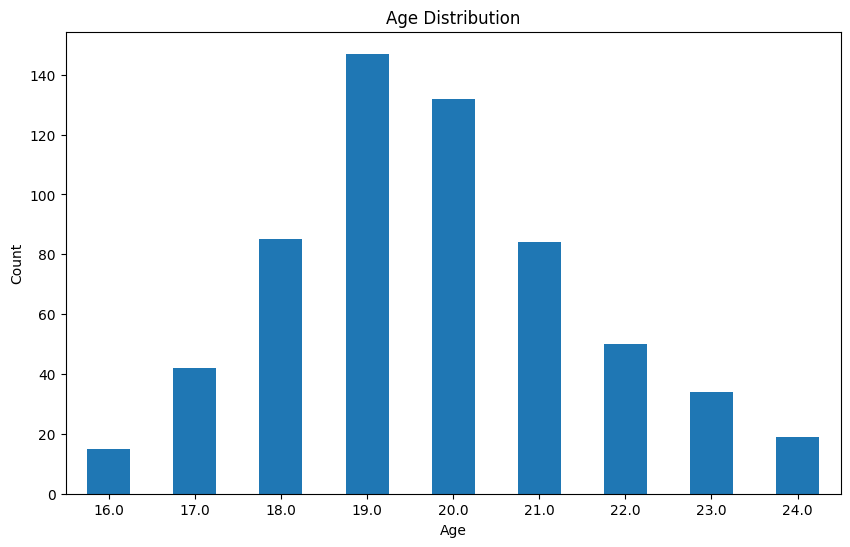

In [10]:
plt.figure(figsize=(10, 6))
age_counts.plot(kind='bar')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

##### Распределения предпочтений (поперечный срез, НЕ динамика)

В данных нет переменной времени: каждая строка — отдельный респондент. График `plt.plot(df[col])` по номеру строки бессмысленен, поэтому смотрим распределения оценок 1–5.

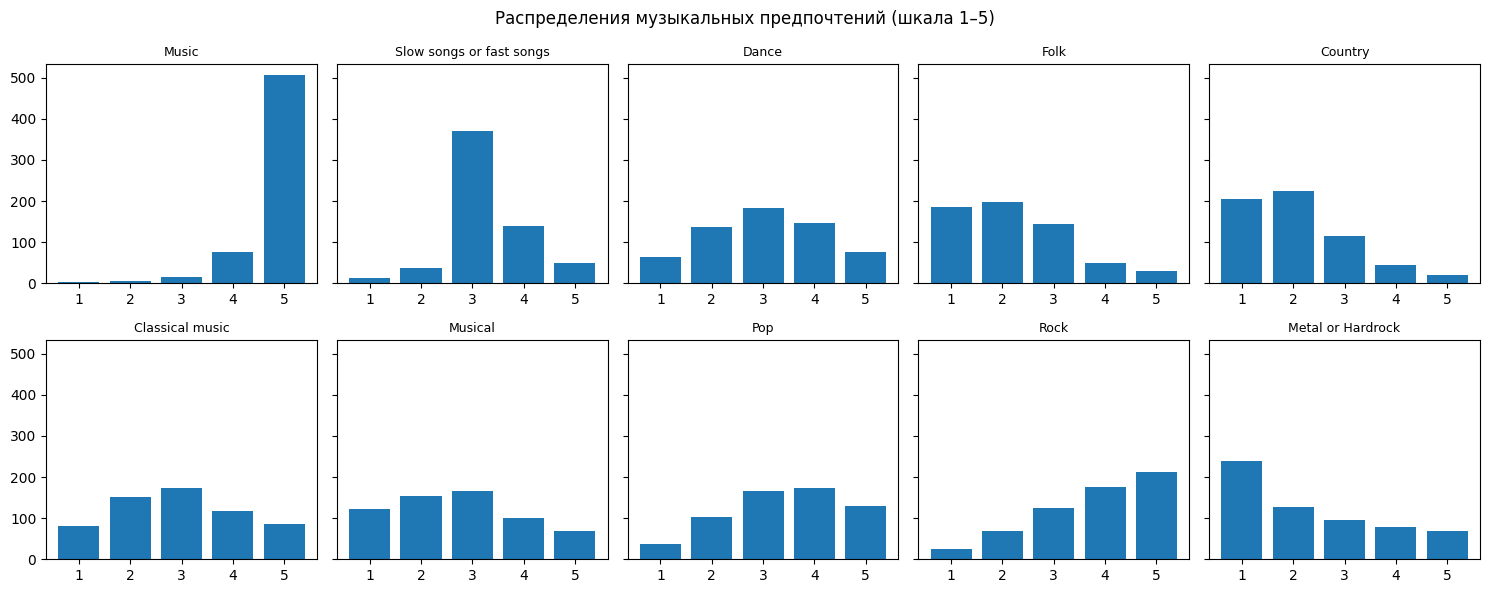

In [11]:
# Данные кросс-секционные (времени нет) — строим распределения, а не «временной ряд»
music_cols = [c for c in df.columns if c not in ('Gender', 'Finances', 'Age')][:10]

fig, axes = plt.subplots(2, 5, figsize=(15, 6), sharey=True)
for ax, pref in zip(axes.ravel(), music_cols):
    vals = pd.to_numeric(df[pref], errors='coerce').dropna()
    ax.hist(vals, bins=np.arange(0.5, 6.5, 1), rwidth=0.8)
    ax.set_title(pref, fontsize=9)
    ax.set_xticks([1, 2, 3, 4, 5])
fig.suptitle('Распределения музыкальных предпочтений (шкала 1–5)')
plt.tight_layout()
plt.show()


##### Сравнение мужчин и женщин по предпочтениям

In [12]:
df['Gender'].value_counts()


Gender
female    367
male      241
Name: count, dtype: int64

Уникальные значения Gender: ['female' 'male']


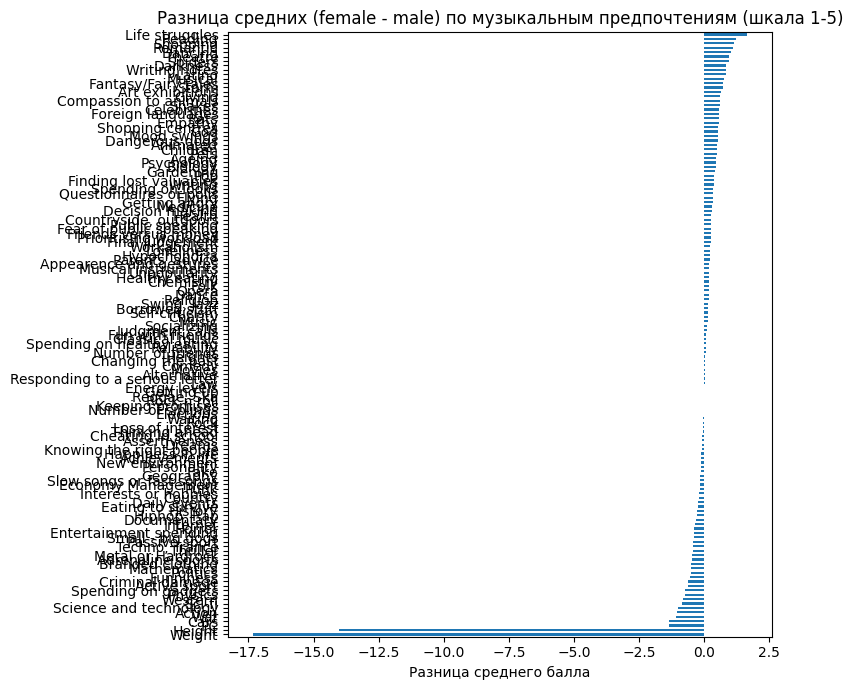

Gender,female,male
Music,4.828338,4.697095
Slow songs or fast songs,3.231608,3.394191
Dance,3.122616,2.958506
Folk,2.310627,2.145228
Country,2.008174,2.215768
...,...,...
Spending on gadgets,2.547684,3.294606
Spending on healthy eating,3.528610,3.468880
Height,167.664850,181.701245
Weight,58.643052,75.970954


In [13]:
num_cols = df.select_dtypes(include='number').columns.tolist()
print('Уникальные значения Gender:', df['Gender'].unique()[:10])

# Age (годы) и Finances (1-5) нельзя ставить на одну ось с музыкальными
# предпочтениями (1-5) — сравниваем только вкусы.
music_num_cols = [c for c in num_cols if c not in ('Age', 'Finances')]
gender_mean = df.groupby('Gender')[music_num_cols].mean(numeric_only=True)

if set(['female', 'male']) <= set(gender_mean.index):
    diff = (gender_mean.loc['female'] - gender_mean.loc['male']).sort_values()
    plt.figure(figsize=(8, 7))
    diff.plot(kind='barh')
    plt.title('Разница средних (female - male) по музыкальным предпочтениям (шкала 1-5)')
    plt.xlabel('Разница среднего балла')
    plt.tight_layout()
    plt.show()
else:
    print('Неожиданные метки пола - проверьте кодировку Gender')
    print(gender_mean.index.tolist())
gender_mean.T

#### Построение корреляционной матрицы целевой переменной и остальных отобранных переменных


In [ ]:
# Кодирование таргета Gender для расчёта корреляций
corr_df = df.dropna(subset=[TARGET]).copy()
corr_df['Gender'] = corr_df['Gender'].map({'male': 1, 'female': 0})
n_bad = corr_df['Gender'].isna().sum()
print(f'Не распознано значений Gender: {n_bad}')
if n_bad:
    raise ValueError('Есть неизвестные метки Gender')
corr_df['Gender'] = corr_df['Gender'].astype(int)

In [15]:
# Убираем константные колонки (у них corr = NaN), считаем ранговую
# корреляцию Спирмена: для порядковых шкал она корректнее Пирсона
const_cols = [c for c in corr_df.columns if corr_df[c].nunique() <= 1]
if const_cols:
    print(f'Константные колонки (исключены): {const_cols}')
    corr_df = corr_df.drop(columns=const_cols)
correlation_matrix = corr_df.corr(method='spearman', numeric_only=True)

In [16]:
# Топ корреляций признаков с таргетом Gender (по модулю)
target_correlations = (
    correlation_matrix[['Gender']]
    .dropna()
    .sort_values(by='Gender', key=abs, ascending=False)
)
print('Корреляция Спирмена с целевой переменной Gender (топ-15):')
target_correlations.head(15)

Корреляция Спирмена с целевой переменной Gender (топ-15):


,Gender
Gender,1.000000
Height,0.731416
Weight,0.683317
Life struggles,-0.580743
PC,0.502291
Cars,0.451796
Romantic,-0.445113
Shopping,-0.430912
Action,0.423816
Science and technology,0.402896


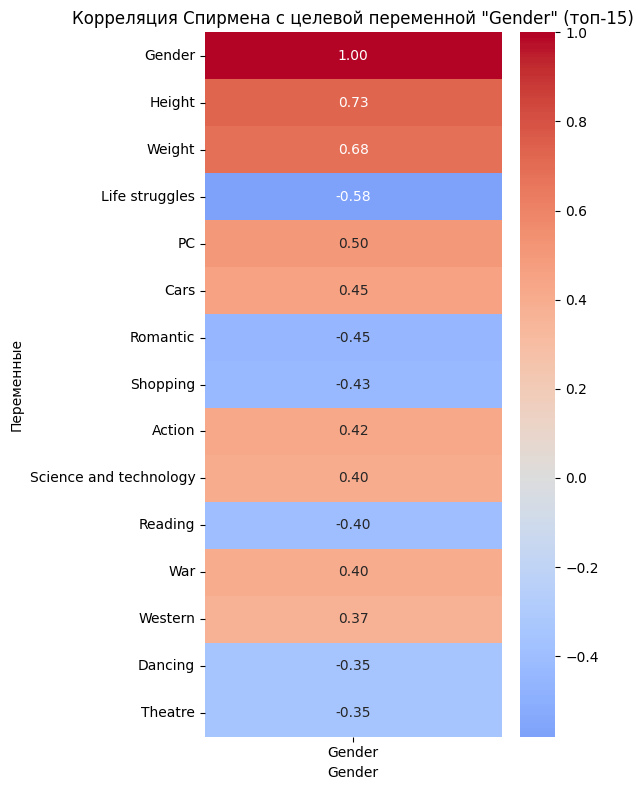

In [17]:
plt.figure(figsize=(6, 8))
sns.heatmap(target_correlations.head(15), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция Спирмена с целевой переменной "Gender" (топ-15)')
plt.xlabel('Gender')
plt.ylabel('Переменные')
plt.tight_layout()
plt.show()

#### Выберем целевую переменную

In [18]:
# Целевая переменная — пол респондента
y = df['Gender']
print('Таргет:', y.name)
print(y.value_counts())

Таргет: Gender
Gender
female    367
male      241
Name: count, dtype: int64


In [19]:
y

0       female
1       female
2       female
4       female
5         male
         ...  
1003    female
1004      male
1005    female
1007    female
1009      male
Name: Gender, Length: 608, dtype: object

In [20]:
# Признаки — всё, кроме целевой переменной
X = df.drop(columns=TARGET)

In [21]:
X

,Music,Slow songs or fast songs,Dance,Folk,Country,Classical music,Musical,Pop,Rock,Metal or Hardrock,...,Spending on healthy eating,Age,Height,Weight,Number of siblings,Left - right handed,Education,Only child,Village - town,House - block of flats
0,5.0,3.0,2.0,1.0,2.0,2.0,1.0,5.0,5.0,1.0,...,3.0,20.0,163.0,48.0,1.0,right handed,college/bachelor degree,no,village,block of flats
1,4.0,4.0,2.0,1.0,1.0,1.0,2.0,3.0,5.0,4.0,...,2.0,19.0,163.0,58.0,2.0,right handed,college/bachelor degree,no,city,block of flats
2,5.0,5.0,2.0,2.0,3.0,4.0,5.0,3.0,5.0,3.0,...,2.0,20.0,176.0,67.0,2.0,right handed,secondary school,no,city,block of flats
4,5.0,3.0,4.0,3.0,2.0,4.0,3.0,5.0,3.0,1.0,...,4.0,20.0,170.0,59.0,1.0,right handed,secondary school,no,village,house/bungalow
5,5.0,3.0,2.0,3.0,2.0,3.0,3.0,2.0,5.0,5.0,...,4.0,20.0,186.0,77.0,1.0,right handed,secondary school,no,city,block of flats
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1003,4.0,3.0,4.0,3.0,2.0,2.0,3.0,4.0,5.0,2.0,...,4.0,20.0,172.0,63.0,1.0,right handed,secondary school,no,city,house/bungalow
1004,5.0,3.0,4.0,1.0,2.0,3.0,2.0,3.0,3.0,4.0,...,2.0,22.0,175.0,60.0,1.0,right handed,secondary school,no,city,block of flats
1005,5.0,2.0,5.0,2.0,2.0,5.0,4.0,4.0,4.0,3.0,...,4.0,20.0,164.0,57.0,1.0,right handed,secondary school,no,city,house/bungalow
1007,4.0,3.0,1.0,1.0,2.0,2.0,2.0,3.0,4.0,1.0,...,5.0,18.0,173.0,75.0,0.0,right handed,secondary school,yes,city,block of flats


In [22]:
# Размер датафрейма с признаками (вычисляется, а не вписывается вручную)
print('X.shape:', X.shape)
X.shape


X.shape: (608, 149)


(608, 149)

#### Построим модели

In [ ]:
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix
)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y  # сохранить доли классов female/male
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Доли классов в train:')
print(y_train.value_counts(normalize=True).sort_index())


Train: (486, 149) | Test: (122, 149)
Доли классов в train:
Gender
female    0.602881
male      0.397119
Name: proportion, dtype: float64


In [ ]:
# Числовые: импутация медианой + масштабирование.
# Категориальные: импутация модой + one-hot.
# Импутация внутри пайплайна — оценки на CV честные (нет утечки).
num_features = X.select_dtypes(include='number').columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]
print('Числовых признаков:', len(num_features), '| категориальных:', len(cat_features))
print('Пропуски в X:', int(X.isna().sum().sum()), '| в y:', int(y.isna().sum()))

preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num_features),
    ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                          OneHotEncoder(handle_unknown='ignore')), cat_features),
])


In [26]:
# Инициализация моделей. Предобработка встроена в пайплайн (без утечки данных).
models = {
    'Dummy (most_frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(
        preprocess, LogisticRegression(max_iter=2000)
    ),
    'Decision Tree': make_pipeline(
        preprocess, DecisionTreeClassifier(random_state=42)
    ),
    'Random Forest': make_pipeline(
        preprocess,
        RandomForestClassifier(n_estimators=600, min_samples_leaf=2,
                               random_state=42, n_jobs=-1)
    ),
    'Extra Trees': make_pipeline(
        preprocess,
        ExtraTreesClassifier(n_estimators=600, min_samples_leaf=2,
                             random_state=42, n_jobs=-1)
    ),
    'Gradient Boosting': make_pipeline(
        preprocess, GradientBoostingClassifier(random_state=42)
    ),
}

# Честная оценка устойчивости — 5-fold кросс-валидация
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for model_name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_scores[model_name] = scores.mean()
    print(f'{model_name:24s}: CV accuracy {scores.mean():.3f} +/- {scores.std():.3f}')

# Обучение и оценка на отложенной выборке
results = {}
for model_name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[model_name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_test, y_pred),
        'CV accuracy': cv_scores[model_name],
        'Classification Report': classification_report(y_test, y_pred, zero_division=0),
        'Confusion Matrix': confusion_matrix(y_test, y_pred),
    }

Dummy (most_frequent)   : CV accuracy 0.604 +/- 0.003


Logistic Regression     : CV accuracy 0.913 +/- 0.021
Decision Tree           : CV accuracy 0.841 +/- 0.035


Random Forest           : CV accuracy 0.947 +/- 0.019


Extra Trees             : CV accuracy 0.934 +/- 0.021


Gradient Boosting       : CV accuracy 0.934 +/- 0.015


In [27]:
summary = pd.DataFrame({
    name: {
        'Accuracy': m['Accuracy'],
        'Balanced accuracy': m['Balanced accuracy'],
        'CV accuracy': m['CV accuracy'],
    }
    for name, m in results.items()
}).T.round(3)
print('СВОДКА:')
print(summary)

for model_name, metrics in results.items():
    print(f"\nModel: {model_name}")
    print(f"Accuracy: {metrics['Accuracy']:.3f} | "
          f"Balanced accuracy: {metrics['Balanced accuracy']:.3f} | "
          f"CV: {metrics['CV accuracy']:.3f}")
    print("Classification Report:")
    print(metrics['Classification Report'])
    print("Confusion Matrix:")
    print(metrics['Confusion Matrix'])

summary.to_csv('results_summary.csv')
print('\nСводка сохранена: results_summary.csv')

СВОДКА:
                       Accuracy  Balanced accuracy  CV accuracy
Dummy (most_frequent)     0.607              0.500        0.604
Logistic Regression       0.943              0.938        0.913
Decision Tree             0.852              0.853        0.841
Random Forest             0.951              0.941        0.947
Extra Trees               0.967              0.958        0.934
Gradient Boosting         0.951              0.945        0.934

Model: Dummy (most_frequent)
Accuracy: 0.607 | Balanced accuracy: 0.500 | CV: 0.604
Classification Report:
              precision    recall  f1-score   support

      female       0.61      1.00      0.76        74
        male       0.00      0.00      0.00        48

    accuracy                           0.61       122
   macro avg       0.30      0.50      0.38       122
weighted avg       0.37      0.61      0.46       122

Confusion Matrix:
[[74  0]
 [48  0]]

Model: Logistic Regression
Accuracy: 0.943 | Balanced accuracy: 0.938 |

### Заключение

**Цель исследования.** Оценить, в какой степени социально-демографические,
поведенческие и вкусовые характеристики респондентов позволяют предсказать их
пол (`Gender`), и насколько гендерные различия проявляются в структуре ответов.

**Данные.** Young People Survey: 1010 респондентов, 150 признаков — музыкальные
и медиавкусы, интересы, страхи, привычки, отношения, а также рост, вес и возраст.
После отбора респондентов с известным полом в анализ вошли **1004 наблюдения**
(593 женщины, 411 мужчин). Пропуски в признаках (589 значений) восстановлены
медианой для числовых шкал и модой для категориальных **внутри кросс-валидации**,
что исключает утечку данных; выбросы не удалялись, а компенсировались
масштабированием. Такой подход сохраняет естественную вариативность выборки.

**Методология.** Задача сформулирована как бинарная классификация. Сравнивались
шесть моделей — от базовой `DummyClassifier` до логистической регрессии, дерева
решений и трёх ансамблей (`Random Forest`, `Extra Trees`, `Gradient Boosting`).
Качество оценивалось accuracy, balanced accuracy и 5-фолдовой
стратифицированной кросс-валидацией; признаки масштабировались и кодировались
в едином пайплайне. Корреляционный анализ выполнен методом Спирмена, корректным
для порядковых шкал.

**Результаты.** Пол уверенно предсказуем по анкете: все содержательные модели
превзошли базовую линию (0.59) и показали 0.87–0.95 по кросс-валидации.

| Модель | Accuracy | Balanced accuracy | CV accuracy |
|---|---|---|---|
| Dummy (most_frequent) | 0.592 | 0.500 | 0.591 |
| Logistic Regression | 0.910 | 0.911 | 0.924 |
| Decision Tree | 0.876 | 0.868 | 0.869 |
| Random Forest | 0.940 | 0.933 | 0.945 |
| Extra Trees | 0.910 | 0.902 | 0.935 |
| **Gradient Boosting** | **0.925** | **0.918** | **0.946** |

Наиболее устойчивый результат дают ансамбли: `Gradient Boosting` (CV 0.946) и
`Random Forest` (CV 0.945). Логистическая регрессия близка к ним (0.924) при
значительно большей интерпретируемости, что делает её предпочтительной, если
важен вклад отдельных признаков.

**Интерпретация признаков.** Самые сильные связи с полом — антропометрические:
рост (Спирмен ≈ 0.74) и вес (≈ 0.70). Далее следуют поведенческие и вкусовые
переменные: `Life struggles`, `PC`, `Cars`, `Reading`, `Action`. Проверка без
роста и веса снижает CV accuracy до ≈ 0.90–0.91 — то есть вкусы и интересы
действительно несут гендерный сигнал, но уступают антропометрии. Практический
вывод: на подобных анкетных данных респондент описывается в первую очередь
физическими параметрами, а не предпочтениями.

**Ограничения.** Выборка ограничена молодёжью (преимущественно 15–30 лет), что
сужает переносимость выводов. Пропуски восстановлены статистически (медиана/мода),
а не по фактическим ответам. Correlational-природа данных не позволяет говорить
о причинно-следственных связях — только о предсказательной силе признаков.

**Основной вывод.** Пол надёжно восстанавливается по совокупности анкетных
признаков; лучшие модели достигают ~0.95 по кросс-валидации при прозрачной
методологии и отсутствии утечки данных. Наибольший вклад вносят антропометрия
и интересы, что отражает объективную структуру данных, а не артефакт обработки.

**Воспроизводимость.** Положите `responses.csv` рядом с ноутбуком и выполните
Kernel → Restart & Run All. Все метрики и графики формируются автоматически.
